# Marketing Campaign Performance: Exploratory Data Analysis

**Goal:** understand how advertising drives user acquisition and engagement, and tell the story the data contains.

**Dataset:** [Marketing Campaign Performance (Kaggle)](https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset)

**Key questions**
1. Which channels acquire users most efficiently (CTR, conversion rate, cost per conversion, ROI)?
2. Do more impressions or higher spend translate into more engagement?
3. Which customer segments, audiences, countries and languages respond best?
4. Does campaign duration affect ROI or engagement?
5. Is there seasonality or a trend over time?
6. Which combinations of channel, campaign type and audience perform best, and which waste budget?

**Limitations:** the dataset looks synthetic and has no retention data. `Engagement_Score` is the closest proxy.

## 1. Setup and data loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# The notebook lives in notebooks/, so the data folder is one level up
df = pd.read_csv("../data/marketing_campaign_dataset.csv")

## 2. First inspection

Goal: understand the structure before changing anything (size, column types, nulls, duplicates, value ranges).

In [3]:
# Display the information about the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       200000 non-null  int64  
 1   Company           200000 non-null  str    
 2   Campaign_Type     200000 non-null  str    
 3   Target_Audience   200000 non-null  str    
 4   Duration          200000 non-null  str    
 5   Channel_Used      200000 non-null  str    
 6   Conversion_Rate   200000 non-null  float64
 7   Acquisition_Cost  200000 non-null  str    
 8   ROI               200000 non-null  float64
 9   Location          200000 non-null  str    
 10  Language          200000 non-null  str    
 11  Clicks            200000 non-null  int64  
 12  Impressions       200000 non-null  int64  
 13  Engagement_Score  200000 non-null  int64  
 14  Customer_Segment  200000 non-null  str    
 15  Date              200000 non-null  str    
dtypes: float64(2), int64(4), str(10

In [4]:
# Display the first few rows of the DataFrame
df.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [5]:
# Describes the dataset to get a statistical summary of the numerical columns
df.describe()

,Campaign_ID,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,100000.500000,0.080070,5.002438,549.772030,5507.301520,5.494710
std,57735.171256,0.040602,1.734488,260.019056,2596.864286,2.872581
min,1.000000,0.010000,2.000000,100.000000,1000.000000,1.000000
25%,50000.750000,0.050000,3.500000,325.000000,3266.000000,3.000000
50%,100000.500000,0.080000,5.010000,550.000000,5517.500000,5.000000
75%,150000.250000,0.120000,6.510000,775.000000,7753.000000,8.000000
max,200000.000000,0.150000,8.000000,1000.000000,10000.000000,10.000000


In [6]:
# Check for null values in the dataset
print(f"Number of null values per column:\n{df.isnull().sum()}")

Number of null values per column:
Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64


In [7]:
# Check for duplicated rows in the dataset
print(f"Number of duplicated rows:\n{df.duplicated().sum()}")

Number of duplicated rows:
0


In [8]:
# Check if the column Campaign_ID has unique values
print(f"Does column Campaign_ID has unique values?\n{df['Campaign_ID'].is_unique}")

Does column Campaign_ID has unique values?
True


**What the numerical summary and quality checks tell us**

- **No missing values and no duplicates.** All 16 columns have 200,000 non-null values, there are 0 duplicated rows and every `Campaign_ID` is unique (1 to 200,000). No rows need to be dropped or imputed.
- **All numerical ranges are plausible:**
  - `Conversion_Rate` goes from 0.01 to 0.15 (1% to 15%), with a mean of 0.08.
  - `ROI` goes from 2.00 to 8.00, with a mean of 5.00. There are no negative values, so no campaign in the dataset loses money.
  - `Clicks` goes from 100 to 1,000 and `Impressions` from 1,000 to 10,000.
  - `Engagement_Score` is a 1 to 10 scale, with a mean of 5.49.
- **The values look evenly spread.** In every column the mean is very close to the median, and the quartiles are spaced almost equally between the minimum and the maximum. This is typical of randomly generated data and fits the idea that the dataset is synthetic.
- **`Acquisition_Cost` is missing from this summary** because it is stored as text ("$16,174.00"). It will be converted to a number in the cleaning step.

In [9]:
# Check if any row has more clicks than impressions
print(f"Rows with more clicks than impressions:\n{(df['Clicks'] > df['Impressions']).sum()}")

Rows with more clicks than impressions:
0


**Clicks vs impressions:** there are 0 rows with more clicks than impressions, so this inconsistency does not appear in the data. This matches the ranges in `describe()`: the maximum number of clicks (1,000) equals the minimum number of impressions (1,000), so clicks can never exceed impressions.

In [10]:
# Categorical columns to analyze
# There are 10 text columns, but Acquisition_Cost (a number) and Date (a date) are not categories,
# so only the remaining 8 are kept
columns = df.select_dtypes(include="str").columns
to_exclude = ["Acquisition_Cost", "Date"]
analysis_columns = [col for col in columns if col not in to_exclude]

print(f"Categorical columns to analyze:\n{analysis_columns}")

Categorical columns to analyze:
['Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Location', 'Language', 'Customer_Segment']


In [11]:
# Number of distinct values per categorical column
df[analysis_columns].nunique()

Company             5
Campaign_Type       5
Target_Audience     5
Duration            4
Channel_Used        6
Location            5
Language            5
Customer_Segment    5
dtype: int64

In [12]:
# Show the values and their frequency for each categorical column
for col in analysis_columns:
    print(f"--- {col} ---")         # name of the column as a header
    print(df[col].value_counts())   # show the frequency of each value
    print()                         # print a blank line for better readability

--- Company ---
Company
TechCorp               40237
Alpha Innovations      40051
DataTech Solutions     40012
NexGen Systems         39991
Innovate Industries    39709
Name: count, dtype: int64

--- Campaign_Type ---
Campaign_Type
Influencer      40169
Search          40157
Display         39987
Email           39870
Social Media    39817
Name: count, dtype: int64

--- Target_Audience ---
Target_Audience
Men 18-24      40258
Men 25-34      40023
All Ages       40019
Women 25-34    40013
Women 35-44    39687
Name: count, dtype: int64

--- Duration ---
Duration
30 days    50255
45 days    50100
60 days    49866
15 days    49779
Name: count, dtype: int64

--- Channel_Used ---
Channel_Used
Email         33599
Google Ads    33438
YouTube       33392
Instagram     33392
Website       33360
Facebook      32819
Name: count, dtype: int64

--- Location ---


Location
Miami          40269
New York       40024
Chicago        40010
Los Angeles    39947
Houston        39750
Name: count, dtype: int64

--- Language ---
Language
Mandarin    40255
Spanish     40102
German      39983
English     39896
French      39764
Name: count, dtype: int64

--- Customer_Segment ---
Customer_Segment
Foodies                40208
Tech Enthusiasts       40151
Outdoor Adventurers    40011
Health & Wellness      39888
Fashionistas           39742
Name: count, dtype: int64



**What the categorical columns tell us**

- **No typos or inconsistent labels.** Every column has a small, clean set of values (4 to 6), with no value written in two different ways. No text cleaning is needed for these columns.
- **Categories are almost perfectly balanced.** Columns with 5 values have about 40,000 rows per category (for example, `Company` ranges from 39,709 to 40,237). `Channel_Used` has 6 channels with about 33,000 rows each (32,819 to 33,599), and `Duration` has 4 values with about 50,000 each (49,779 to 50,255). Such an even split is unusual in real marketing data and is another sign that the dataset is synthetic. It also suggests that differences between groups will likely be small.
- **`Duration` only takes 4 values:** 15, 30, 45 and 60 days. It is stored as text ("30 days"). In the cleaning step it will be converted to an integer and renamed `Duration_days`, so the unit is clear from the column name.
- **`Location` contains 5 US cities**, not countries (Miami, New York, Chicago, Los Angeles, Houston), while `Language` includes Mandarin, Spanish, German, English and French. Location-based conclusions will be about cities, not countries.

## 3. Data cleaning and preprocessing

### 3.1 Fixing column types

The first inspection showed that the data has no missing values, no duplicates and no inconsistent labels. The only problems are **three columns stored with the wrong type**:

| Column | Problem | Decision |
|---|---|---|
| `Acquisition_Cost` | Text with a dollar sign and commas (`"$16,174.00"`), so it cannot be used in calculations | Remove `$` and `,` and convert to float (USD) |
| `Duration` | Text with the unit inside the value (`"30 days"`) | Keep only the number, convert to integer and rename to `Duration_days` so the unit is in the column name |
| `Date` | Text (`"2021-01-01"`), so it cannot be used for time analysis | Convert to datetime |

**Why the cleaning code is in `src/cleaning.py` and not in this notebook:** the same cleaning steps are reused by the notebook and by the data pipeline, so they are written once as functions. Each function has tests in `tests/test_cleaning.py` that were written before the function itself, checking for example that `"$16,174.00"` becomes `16174.0`. To run them, use `pytest` from the repo root.

In [13]:
import sys

# The notebook runs from notebooks/, so add the repo root to the path to import src/
sys.path.append("..")
from src.cleaning import clean_campaigns

# Keep the raw data in df and work on a cleaned copy
df_clean = clean_campaigns(df)
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Campaign_ID       200000 non-null  int64         
 1   Company           200000 non-null  str           
 2   Campaign_Type     200000 non-null  str           
 3   Target_Audience   200000 non-null  str           
 4   Duration_days     200000 non-null  int64         
 5   Channel_Used      200000 non-null  str           
 6   Conversion_Rate   200000 non-null  float64       
 7   Acquisition_Cost  200000 non-null  float64       
 8   ROI               200000 non-null  float64       
 9   Location          200000 non-null  str           
 10  Language          200000 non-null  str           
 11  Clicks            200000 non-null  int64         
 12  Impressions       200000 non-null  int64         
 13  Engagement_Score  200000 non-null  int64         
 14  Customer_Segmen

In [14]:
# Compare the same rows before and after cleaning
print("Before cleaning:")
print(df[["Acquisition_Cost", "Duration", "Date"]].head(3))
print("\nAfter cleaning:")
print(df_clean[["Acquisition_Cost", "Duration_days", "Date"]].head(3))

Before cleaning:
  Acquisition_Cost Duration        Date
0       $16,174.00  30 days  2021-01-01
1       $11,566.00  60 days  2021-01-02
2       $10,200.00  30 days  2021-01-03

After cleaning:
   Acquisition_Cost  Duration_days       Date
0           16174.0             30 2021-01-01
1           11566.0             60 2021-01-02
2           10200.0             30 2021-01-03


In [15]:
# Check the new columns: value ranges and date coverage
print(df_clean[["Acquisition_Cost", "Duration_days"]].describe())
print(f"\nDate range: {df_clean['Date'].min().date()} to {df_clean['Date'].max().date()}")
print(f"Distinct dates: {df_clean['Date'].nunique()}")

       Acquisition_Cost  Duration_days
count     200000.000000  200000.000000
mean       12504.393040      37.503975
std         4337.664545      16.746720
min         5000.000000      15.000000
25%         8739.750000      30.000000
50%        12496.500000      30.000000
75%        16264.000000      45.000000
max        20000.000000      60.000000

Date range: 2021-01-01 to 2021-12-31
Distinct dates: 365


**What the cleaning changed**

- **All conversions worked on every row.** `df_clean` still has 200,000 rows and 0 missing values, so no value failed to convert. The row-by-row comparison shows that `"$16,174.00"` became `16174.0`, `"30 days"` became `30` and the dates kept the same value with a datetime type.
- **`Acquisition_Cost` goes from 5,000 to 20,000 USD**, with a mean of 12,504 USD. Like the other numerical columns, the mean is very close to the median (12,496.50), which again points to evenly spread, generated data.
- **`Duration_days`** now holds the 4 numeric values 15, 30, 45 and 60, so it can be used in calculations and correlations.
- **`Date` covers the full year 2021** (2021-01-01 to 2021-12-31) with all 365 days present. Since there are 200,000 campaigns, each date has many campaigns, which makes monthly or weekly trends possible.
- **The raw data is kept in `df`** and all the analysis from here uses `df_clean`. This way the original values are always available to compare.

### 3.2 Derived metrics (feature engineering)

The dataset gives raw counts and rates, but the key questions are about **efficiency**, so new metrics are needed. The dataset does not define two of its columns, so these **assumptions** are made:

- `Conversion_Rate` is **conversions / clicks**, the usual marketing definition.
- `Acquisition_Cost` is the **total spend of the campaign** in USD. Its range (5,000 to 20,000 USD) fits a campaign budget, not a cost per customer.

| New column | Formula | What it measures |
|---|---|---|
| `CTR` | Clicks / Impressions | How attractive the ad is |
| `Conversions` | Clicks × Conversion_Rate | Estimated customers acquired |
| `CPC` | Acquisition_Cost / Clicks | Cost per click (USD) |
| `Cost_per_Conversion` | Acquisition_Cost / Conversions | Cost per acquired customer (USD), the main efficiency metric |
| `CPM` | Acquisition_Cost / Impressions × 1,000 | Cost per 1,000 impressions (USD). Normalizes reach cost so campaigns of different sizes can be compared fairly |
| `Month`, `Weekday` | From `Date` | Used for seasonality |

The functions are in `src/features.py` and tested in `tests/test_features.py`. The tests use one row with easy numbers (500 clicks, 2,000 impressions, 10% conversion, 10,000 USD) so every expected result can be checked by hand.

In [16]:
from src.features import add_features

df_clean = add_features(df_clean)
df_clean[["Clicks", "Impressions", "Conversion_Rate", "Acquisition_Cost",
          "CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM", "Month", "Weekday"]].head()

,Clicks,Impressions,Conversion_Rate,Acquisition_Cost,CTR,Conversions,CPC,Cost_per_Conversion,CPM,Month,Weekday
0,506,1922,0.04,16174.0,0.263267,20.24,31.964427,799.110672,8415.192508,1,Friday
1,116,7523,0.12,11566.0,0.015419,13.92,99.706897,830.890805,1537.418583,1,Saturday
2,584,7698,0.07,10200.0,0.075864,40.88,17.465753,249.510763,1325.019486,1,Sunday
3,217,1820,0.11,12724.0,0.119231,23.87,58.635945,533.054043,6991.208791,1,Monday
4,379,4201,0.05,16452.0,0.090217,18.95,43.408971,868.179420,3916.210426,1,Tuesday


In [17]:
# Summary of the new metrics, and how many campaigns have an unrealistic CTR
new_metrics = ["CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM"]
print(df_clean[new_metrics].describe().round(3))

high_ctr = (df_clean["CTR"] > 0.5).sum()
print(f"\nCampaigns with CTR above 50%: {high_ctr} ({high_ctr / len(df_clean):.1%})")

              CTR  Conversions         CPC  Cost_per_Conversion         CPM
count  200000.000   200000.000  200000.000           200000.000  200000.000
mean        0.140       44.023      32.008              635.329    3193.943
std         0.131       32.317      26.926              970.140    2698.980
min         0.010        1.000       5.021               34.218     501.401
25%         0.059       17.760      15.092              180.484    1508.453
50%         0.100       35.760      22.774              334.396    2269.956
75%         0.170       64.100      38.599              692.481    3837.796
max         0.992      150.000     199.960            19432.353   19896.104

Campaigns with CTR above 50%: 6166 (3.1%)


**What the new metrics tell us**

- **The metrics are correct but their scale is not realistic.** The median CTR is 10.0% and 6,166 campaigns (3.1%) have a CTR above 50%, while real ad CTRs are usually a few percent. The median CPM is 2,270 USD, while real CPMs are usually tens of dollars. This is a **data quality limitation of the synthetic dataset**: comparisons *between* groups are still valid, but absolute values should not be read as real-world benchmarks.
- **A typical campaign gets about 36 conversions** (median) at a cost of **334 USD per conversion**.
- **`Cost_per_Conversion` is strongly right-skewed**: the mean (635 USD) is almost twice the median (334 USD) and the maximum reaches 19,432 USD. A few campaigns with very few conversions make the average misleading. For this reason, the analysis will compare groups using the **median**, and a **log scale** will be used when plotting this metric.
- These extreme values are checked as outliers in the next step.

### 3.3 Outliers (IQR rule)

An outlier is a value far from the rest. The **IQR rule** defines "far" in a simple, standard way:

- **IQR** (interquartile range) = Q3 − Q1, the width of the middle 50% of the data.
- A value is an outlier if it is **below Q1 − 1.5 × IQR** or **above Q3 + 1.5 × IQR**.

The functions `iqr_bounds` and `flag_outliers_iqr` are in `src/quality.py` and tested in `tests/test_quality.py`. Here they are applied to every numerical column, original and derived.

In [18]:
from src.quality import flag_outliers_iqr, iqr_bounds

# Count outliers in every numerical column, original and derived
numeric_cols = ["Conversion_Rate", "ROI", "Acquisition_Cost", "Clicks", "Impressions",
                "Engagement_Score", "CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM"]

rows = []
for col in numeric_cols:
    low, high = iqr_bounds(df_clean[col])
    n_outliers = flag_outliers_iqr(df_clean[col]).sum()
    rows.append({"column": col, "lower_limit": low, "upper_limit": high,
                 "outliers": n_outliers, "outliers_pct": n_outliers / len(df_clean) * 100})

outlier_summary = pd.DataFrame(rows).set_index("column").round(2)
outlier_summary

,lower_limit,upper_limit,outliers,outliers_pct
column,,,,
Conversion_Rate,-0.05,0.22,0,0.00
ROI,-1.01,11.02,0,0.00
Acquisition_Cost,-2546.62,27550.38,0,0.00
Clicks,-350.00,1450.00,0,0.00
Impressions,-3464.50,14483.50,0,0.00
Engagement_Score,-4.50,15.50,0,0.00
CTR,-0.11,0.34,16141,8.07
Conversions,-51.75,133.61,1563,0.78
CPC,-20.17,73.86,16044,8.02


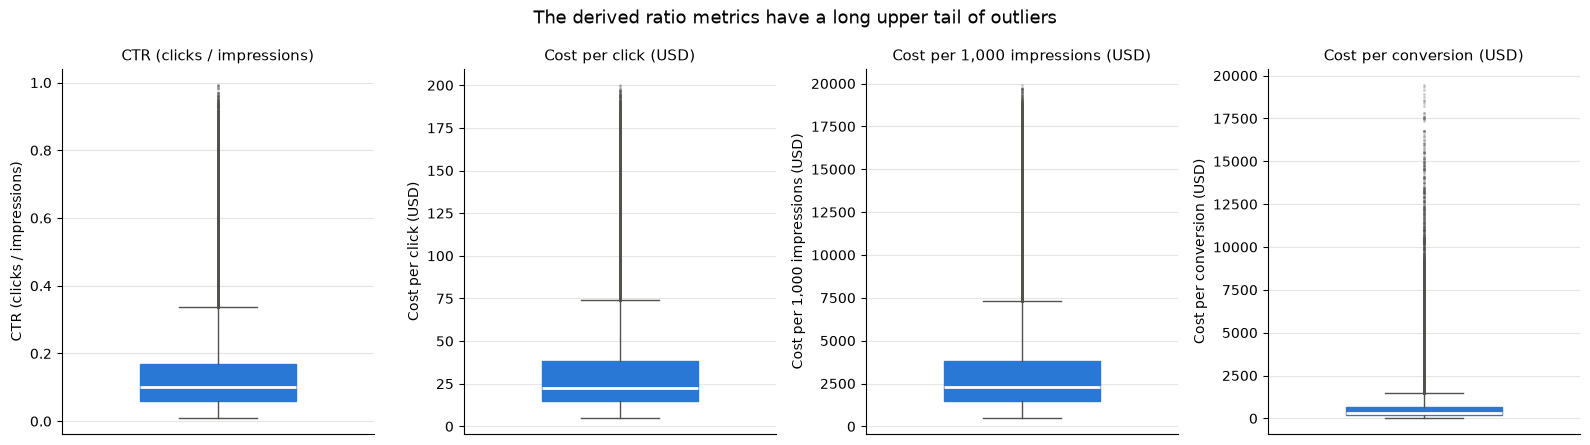

In [19]:
# Boxplots of the four metrics with outliers, one panel each because their scales differ
plot_metrics = {
    "CTR": "CTR (clicks / impressions)",
    "CPC": "Cost per click (USD)",
    "CPM": "Cost per 1,000 impressions (USD)",
    "Cost_per_Conversion": "Cost per conversion (USD)",
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, plot_metrics.items()):
    ax.boxplot(
        df_clean[col],
        widths=0.5,
        patch_artist=True,
        boxprops={"facecolor": "#2a78d6", "color": "#2a78d6"},
        medianprops={"color": "white", "linewidth": 2},
        whiskerprops={"color": "#52514e"},
        capprops={"color": "#52514e"},
        flierprops={"marker": "o", "markersize": 2, "markerfacecolor": "#52514e",
                    "markeredgecolor": "none", "alpha": 0.3},
    )
    ax.set_title(label, fontsize=11)
    ax.set_ylabel(label)
    ax.set_xticks([])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("The derived ratio metrics have a long upper tail of outliers", fontsize=13)
plt.tight_layout()
plt.show()

**What the outlier check tells us**

- **The original columns have no outliers at all.** `Conversion_Rate`, `ROI`, `Acquisition_Cost`, `Clicks`, `Impressions` and `Engagement_Score` all have 0 values outside the IQR limits. Their values are spread evenly between a fixed minimum and maximum, so there are no extreme cases.
- **Outliers only appear in the derived ratio metrics**, about 8% to 9% of the campaigns for `CTR`, `CPC`, `CPM` and `Cost_per_Conversion`. Dividing one evenly spread column by another produces a long right tail: when the denominator is small (few impressions, few clicks or few conversions), the ratio becomes very large. The boxplots show this long upper tail.
- **Decision: keep all outliers and flag them.** They are not data errors. They are campaigns where the cost was spread over very few results, which is exactly what question 6 (budget waste) needs to find. Removing them would hide the most inefficient campaigns.

In [20]:
# Flag the high-cost campaigns (kept in the data) and compare them with the rest
df_clean["High_Cost_Outlier"] = flag_outliers_iqr(df_clean["Cost_per_Conversion"])

compare_cols = ["Cost_per_Conversion", "Conversions", "Clicks", "Conversion_Rate",
                "Acquisition_Cost", "ROI", "Engagement_Score"]
comparison = df_clean.groupby("High_Cost_Outlier")[compare_cols].median().round(2)
comparison.index = ["Normal campaigns", "High-cost outliers"]
comparison

,Cost_per_Conversion,Conversions,Clicks,Conversion_Rate,Acquisition_Cost,ROI,Engagement_Score
Normal campaigns,298.29,39.80,582.0,0.09,12156.0,5.01,5.0
High-cost outliers,2229.12,6.14,232.0,0.02,15444.0,5.00,5.0


**Who are the high-cost outliers?**

The 18,445 campaigns flagged in `High_Cost_Outlier` (9.2%) are kept in the data and compared with the rest using medians:

- **They pay about 7 times more per customer**: 2,229 USD per conversion vs 298 USD for normal campaigns.
- **The cause is low results, not only high spend.** They get far fewer clicks (232 vs 582), a much lower conversion rate (2% vs 9%) and therefore only about 6 conversions vs 40. Their spend is also higher (15,444 vs 12,156 USD), which makes the cost per conversion even worse.
- **Their ROI is the same as normal campaigns (5.00 vs 5.01)**, and so is their engagement (5 vs 5). In real data, a campaign that pays 7 times more per customer should have a much lower ROI. This shows that **the `ROI` column is not consistent with the cost and conversion columns**, so ROI cannot be trusted alone to judge efficiency. The analysis will use `Cost_per_Conversion` as the main efficiency metric and report ROI separately, with this limitation stated.

### 3.4 Second data source: US public holidays (API + merge)

To check whether campaigns behave differently on holidays (question 5, seasonality), the data is enriched with the **US public holidays of 2021** from the free [Nager.Date API](https://date.nager.at), downloaded with `requests`.

Decisions:

- **Only federal holidays are kept** (`"global": true` in the API). The 5 cities are in 5 different states (New York, California, Illinois, Texas and Florida), so state-only holidays do not apply to all of them.
- **One row per date.** The API returns some dates more than once (for example 11 October appears 3 times). If the holiday table had a repeated date, the merge would **duplicate** every campaign of that day, so duplicates are dropped first.
- **Left merge on `Date`**, so every campaign is kept exactly once, and campaigns on normal days get `Is_Holiday = False`.
- **Local cache.** The first run downloads the holidays and saves them to `data/us_holidays_2021.csv`. Later runs read that file, so the notebook also works offline and always uses the same data.

Each campaign has a single `Date`, which is read here as its **start date**.

In [21]:
from src.holidays import load_us_holidays

# Downloads from the API with requests the first time, then reads the saved CSV
holidays = load_us_holidays(2021, "../data/us_holidays_2021.csv")
holidays

,Date,Holiday_Name
0,2021-01-01,New Year's Day
1,2021-01-18,"Martin Luther King, Jr. Day"
2,2021-02-15,Presidents Day
3,2021-05-31,Memorial Day
4,2021-06-18,Juneteenth National Independence Day
5,2021-07-05,Independence Day
6,2021-09-06,Labour Day
7,2021-10-11,Columbus Day
8,2021-11-11,Veterans Day
9,2021-11-25,Thanksgiving Day


In [22]:
from src.holidays import add_holiday_flag

# Left merge on Date: every campaign is kept, holiday columns are added
rows_before = len(df_clean)
df_clean = add_holiday_flag(df_clean, holidays)

print(f"Rows before merge: {rows_before:,} | after merge: {len(df_clean):,}")
print(f"Campaigns that started on a federal holiday: {df_clean['Is_Holiday'].sum():,} "
      f"({df_clean['Is_Holiday'].mean():.1%})")
df_clean.loc[df_clean["Is_Holiday"], "Holiday_Name"].value_counts()

Rows before merge: 200,000 | after merge: 200,000
Campaigns that started on a federal holiday: 6,027 (3.0%)


Holiday_Name
New Year's Day                          548
Martin Luther King, Jr. Day             548
Presidents Day                          548
Memorial Day                            548
Juneteenth National Independence Day    548
Independence Day                        548
Labour Day                              548
Columbus Day                            548
Veterans Day                            548
Thanksgiving Day                        548
Christmas Day                           547
Name: count, dtype: int64

In [23]:
# Check how dates are assigned: campaigns per date, and whether the date
# simply follows the campaign ID in a 365-day rotation
campaigns_per_date = df_clean["Date"].value_counts()
print(f"Campaigns per date: min {campaigns_per_date.min()}, max {campaigns_per_date.max()}")

rotation_date = pd.Timestamp("2021-01-01") + pd.to_timedelta((df_clean["Campaign_ID"] - 1) % 365, unit="D")
print(f"Rows where Date = 1 Jan + (Campaign_ID - 1) mod 365 days: {(df_clean['Date'] == rotation_date).mean():.1%}")

Campaigns per date: min 547, max 548
Rows where Date = 1 Jan + (Campaign_ID - 1) mod 365 days: 100.0%


**What the merge tells us**

- **The merge worked as intended**: 200,000 rows before and after, so no campaign was duplicated or lost.
- **The API returned 11 federal holidays for 2021.** Two of them are *observed* dates: Independence Day appears on 5 July and Christmas Day on 24 December, because 4 July 2021 was a Sunday and 25 December 2021 was a Saturday.
- **6,027 campaigns (3.0%) started on a federal holiday**, with 547 or 548 campaigns on each holiday.
- **Data quality finding: dates are assigned in a fixed rotation.** Every date has exactly 547 or 548 campaigns, and checking the IDs shows that campaign 1 starts on 1 January, campaign 2 on 2 January and so on, starting over every 365 campaigns. This holds for 100% of the rows. In other words, **the date depends only on the campaign ID**, not on any business decision. Real campaigns would cluster around key periods (Black Friday, Christmas, summer). This means **seasonality and holiday effects cannot really exist in this dataset**. Question 5 will still be checked, but a flat result is the expected outcome and will be reported as such.

### 3.5 Reproducible pipeline

All the steps of this section (type fixes, derived metrics, outlier flag and holiday merge) are also chained in `src/pipeline.py`, using the same tested functions. From the repo root, one command rebuilds the processed dataset:

```bash
python -m src.pipeline
```

It saves `data/processed/campaigns_clean.csv` (200,000 rows, 26 columns). The file is not committed to the repo because it can always be regenerated from the raw CSV.

## 4. Exploratory analysis

Each subsection answers one key question with a summary table, a chart and a short reading. Two rules apply to all of them, based on what the cleaning showed:

- **Groups are compared with medians**, not means, because the cost metrics are strongly skewed.
- **Every comparison is checked with a statistical test.** The dataset is synthetic and its groups are almost identical in size, so small differences between medians can be pure noise. The **Kruskal-Wallis test** (`src/significance.py`, tested in `tests/test_significance.py`) tells whether the groups really differ:
  - **p-value < 0.05** means the difference is unlikely to be chance.
  - **Effect size (ε²)** says how much the grouping matters: around 0.01 is small, 0.08 moderate, 0.26 large. With 200,000 rows, a tiny difference can be "significant" but irrelevant, so both numbers are needed.

Kruskal-Wallis is used instead of ANOVA because it compares ranks, not raw values, so it does not need normally distributed data and outliers do not distort it.

### 4.1 Which channels acquire customers most efficiently?

Efficiency is measured at every step of the funnel: attracting clicks (`CTR`), turning clicks into customers (`Conversion_Rate`) and the cost of each customer (`Cost_per_Conversion`, the main metric), plus `CPC`, `CPM`, `ROI` and `Engagement_Score`. `High_Cost_Share` is the share of each channel's campaigns flagged as high-cost outliers in section 3.3.

In [24]:
# Median of each efficiency metric per channel, plus volume and share of high-cost campaigns
channel_summary = df_clean.groupby("Channel_Used").agg(
    Campaigns=("Campaign_ID", "count"),
    CTR=("CTR", "median"),
    Conversion_Rate=("Conversion_Rate", "median"),
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    CPC=("CPC", "median"),
    CPM=("CPM", "median"),
    ROI=("ROI", "median"),
    Engagement_Score=("Engagement_Score", "median"),
    High_Cost_Share=("High_Cost_Outlier", "mean"),
).sort_values("Cost_per_Conversion")

channel_summary.round({"CTR": 4, "Conversion_Rate": 2, "Cost_per_Conversion": 1, "CPC": 2,
                       "CPM": 0, "ROI": 3, "High_Cost_Share": 4})

,Campaigns,CTR,Conversion_Rate,Cost_per_Conversion,CPC,CPM,ROI,Engagement_Score,High_Cost_Share
Channel_Used,,,,,,,,,
Website,33360,0.1001,0.08,330.5,22.68,2272.0,5.030,6.0,0.0915
Email,33599,0.1001,0.08,331.2,22.79,2270.0,5.000,5.0,0.0906
Google Ads,33438,0.0991,0.08,334.3,22.73,2257.0,5.010,5.0,0.0947
Facebook,32819,0.0999,0.08,336.4,22.84,2278.0,5.040,6.0,0.0920
YouTube,33392,0.0998,0.08,337.0,22.71,2265.0,4.970,6.0,0.0919
Instagram,33392,0.0998,0.08,337.3,22.93,2276.0,4.985,5.0,0.0927


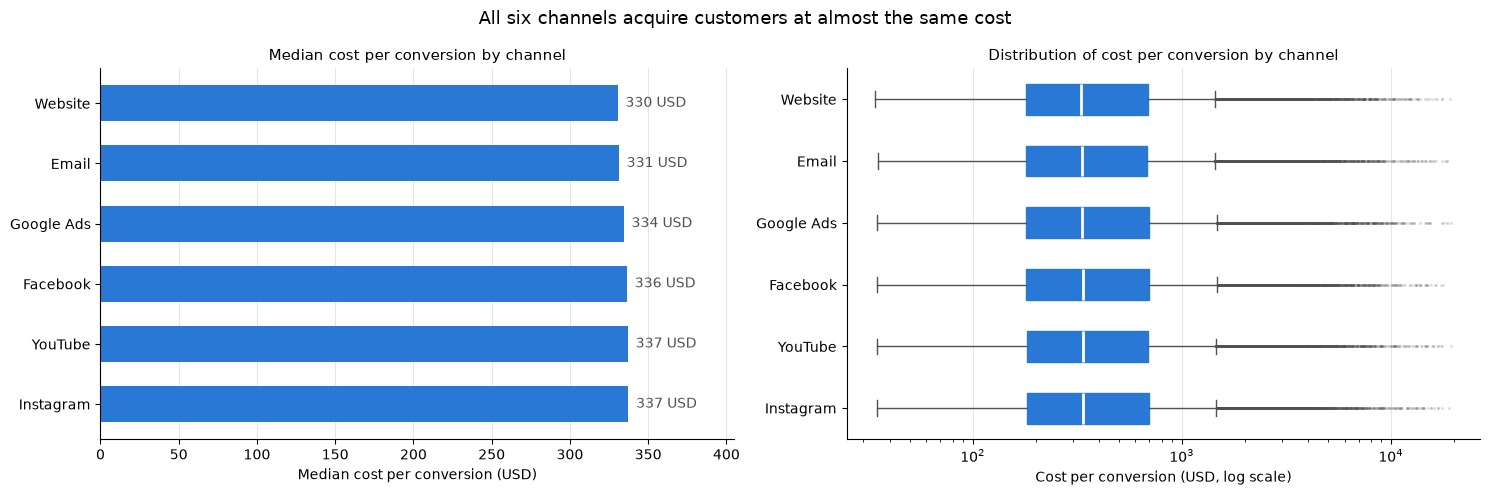

In [25]:
BLUE = "#2a78d6"    # main color for single-series charts
GRAY = "#52514e"    # secondary ink for whiskers, labels and outliers
GRID = "#e5e5e2"

# Horizontal charts draw the first item at the bottom, so sort descending to put the cheapest on top
channel_order = channel_summary.sort_values("Cost_per_Conversion", ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: median cost per conversion, axis starting at 0 so differences are not exaggerated
medians = channel_summary.loc[channel_order, "Cost_per_Conversion"]
ax1.barh(channel_order, medians, color=BLUE, height=0.6)
for y, value in enumerate(medians):
    ax1.text(value + 5, y, f"{value:,.0f} USD", va="center", color=GRAY, fontsize=10)
ax1.set_xlim(0, medians.max() * 1.2)
ax1.set_xlabel("Median cost per conversion (USD)")
ax1.set_title("Median cost per conversion by channel", fontsize=11)

# Right: full distribution on a log scale, because the metric is strongly skewed
data = [df_clean.loc[df_clean["Channel_Used"] == ch, "Cost_per_Conversion"] for ch in channel_order]
ax2.boxplot(
    data, orientation="horizontal", tick_labels=channel_order, widths=0.5, patch_artist=True,
    boxprops={"facecolor": BLUE, "color": BLUE},
    medianprops={"color": "white", "linewidth": 2},
    whiskerprops={"color": GRAY}, capprops={"color": GRAY},
    flierprops={"marker": "o", "markersize": 2, "markerfacecolor": GRAY,
                "markeredgecolor": "none", "alpha": 0.2},
)
ax2.set_xscale("log")
ax2.set_xlabel("Cost per conversion (USD, log scale)")
ax2.set_title("Distribution of cost per conversion by channel", fontsize=11)

for ax in (ax1, ax2):
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("All six channels acquire customers at almost the same cost", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q1_channels_cost_per_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
from src.significance import compare_groups

# Do the channels really differ? One Kruskal-Wallis test per metric
efficiency_metrics = ["CTR", "Conversion_Rate", "Cost_per_Conversion", "CPC", "CPM", "ROI", "Engagement_Score"]
channel_tests = compare_groups(df_clean, "Channel_Used", efficiency_metrics)
channel_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6})

,H,p_value,epsilon_squared,significant
metric,,,,
CTR,5.42,0.367,0.000002,False
Conversion_Rate,2.90,0.715,0.000000,False
Cost_per_Conversion,5.96,0.310,0.000005,False
CPC,3.80,0.578,0.000000,False
CPM,1.32,0.933,0.000000,False
ROI,7.72,0.172,0.000014,False
Engagement_Score,1.85,0.870,0.000000,False


**Answer to question 1: no channel acquires customers more efficiently than the others.**

- **The medians are almost identical.** Median cost per conversion goes from 330.5 USD (Website) to 337.3 USD (Instagram), a gap of under 7 USD (about 2%). CTR is 9.9% to 10.0% in every channel, conversion rate is 8% in all of them, and median ROI goes from 4.97 to 5.04.
- **The full distributions overlap completely.** On the log-scale boxplots, the boxes, whiskers and outlier tails of the six channels are the same. The share of high-cost campaigns is also similar everywhere (9.1% to 9.5%).
- **The statistical test confirms it is noise.** No metric shows a significant difference between channels: all p-values are between 0.17 and 0.93, well above 0.05, and the effect size ε² is practically 0 (at most 0.000014). The ranking in the table would change with a different sample.
- **The engagement medians of 5 vs 6** look like a difference, but `Engagement_Score` is a whole number from 1 to 10, so the median jumps from one integer to the next. The test (p = 0.87) shows the channels do not differ.

**What it means for the business:** in this data, *choosing a channel* is not a lever to cut acquisition costs. The difference between a good and a bad campaign happens **inside** each channel (section 3.3 found 9.2% high-cost campaigns spread evenly across all of them), so budget decisions should look at campaign-level results rather than at the channel.

## 5. Conclusions and recommendations

_TODO: write once the analysis is done._